# Column spatial-similarity QC

This notebook reads cached native physical-space QC results produced by `spatial_similarity_qc_v2.py`. The expensive pair sampling and 21-point MD profile comparisons are performed on compute nodes; this notebook only summarizes the cached tables.

For each subject × hemisphere × aparc region, the analysis uses cleaned MD column profiles and their corresponding first-depth (white-surface) trajectory anchors. Anchor coordinates are converted from DWI voxel indices to physical millimetres using the preprocessed DWI affine.

Nearby pairs are the 20 nearest valid columns. Distant pairs are 20 valid columns sampled from the farthest 25% of columns in the same subject × hemisphere × region. A region contributes to the paired comparison only when it has at least 41 usable columns. The cached QC also records original, cleaned, and usable column counts, so exclusions caused by cleaning are explicit.

Profile similarity is quantified with Pearson correlation (profile shape), RMSE, and MAE (absolute profile difference). Positive `delta_r`, `delta_rmse`, and `delta_mae` all indicate that nearby columns are more similar than distant columns.

A separate random-pair sample within each group estimates the continuous relationship between anchor distance and profile similarity. These distances are Euclidean distances in transformed DWI physical space, not cortical-surface geodesic distances; therefore, the analysis is an initial spatial QC rather than a definitive surface-geodesic analysis.


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.stats import wilcoxon

QC_ROOT=Path('/mnt/newStor/paros/paros_WORK/xintong/results/spatial_similarity_qc_v2')
SUMMARY=QC_ROOT/'spatial_similarity_group_summary_v2.csv'
BINS=QC_ROOT/'spatial_similarity_distance_bins_v2.csv'
STATUS=QC_ROOT/'spatial_similarity_group_status_v2.csv'
if not all(p.is_file() for p in (SUMMARY,BINS,STATUS)):
    raise FileNotFoundError('Run submit_spatial_similarity_qc_v2.sbatch first.')
summary=pd.read_csv(SUMMARY); bins=pd.read_csv(BINS); status=pd.read_csv(STATUS)
print(f'Valid subject-region groups: {len(summary):,}; subjects: {summary.subject.nunique():,}')
display(status.status.value_counts(dropna=False).rename_axis('status').reset_index(name='groups'))


Valid subject-region groups: 20,317; subjects: 300


,status,groups
0,valid,20317
1,skipped,83


## 1. Pair-sampling and cleaning QC

These plots first verify that nearby and distant pairs represent clearly different spatial scales. Each valid group contributes `n_columns × 20` nearby comparisons and the same number of distant comparisons.


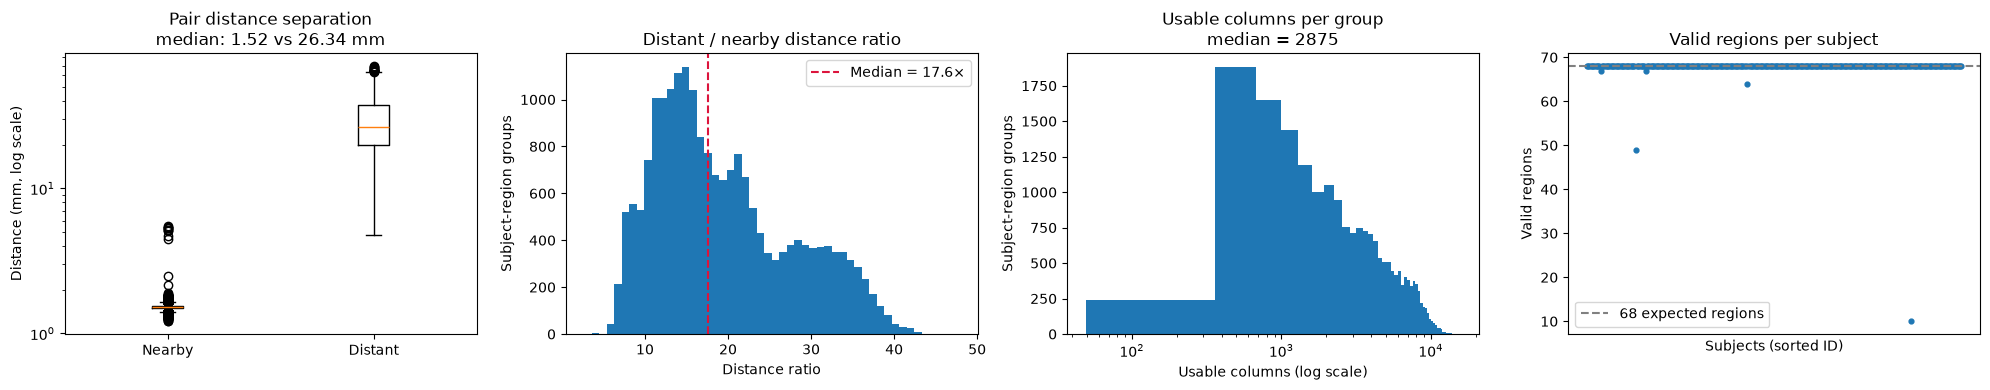

,median_nearby_distance_mm,median_distant_distance_mm,median_distance_ratio,groups_with_distant_over_2x_nearby_pct,median_usable_columns,median_nearby_pair_count,median_distant_pair_count,subjects_with_68_valid_regions,total_subjects
0,1.524891,26.336395,17.562264,100.0,2875.0,57500.0,57500.0,295,300


,count,mean,std,min,25%,50%,75%,max
n_columns,20317.0,3597.782350,2742.246541,49.0,1266.0,2875.0,5371.0,15707.000000
nearby_pair_count,20317.0,71955.646995,54844.930828,980.0,25320.0,57500.0,107420.0,314140.000000
distant_pair_count,20317.0,71955.646995,54844.930828,980.0,25320.0,57500.0,107420.0,314140.000000
continuous_pair_count,20317.0,2999.811783,17.924809,1176.0,3000.0,3000.0,3000.0,3000.000000
cleaning_excluded_pct,20317.0,0.493671,3.603408,0.0,0.0,0.0,0.0,98.835856


In [3]:
near=summary.nearest_mean_distance_mm.dropna(); far=summary.distant_mean_distance_mm.dropna(); ratio=far.to_numpy()/near.to_numpy()
valid_regions=summary.groupby('subject').size()
fig,axes=plt.subplots(1,4,figsize=(20,4))
axes[0].boxplot([near,far],tick_labels=['Nearby','Distant']); axes[0].set_yscale('log'); axes[0].set(title=f'Pair distance separation\nmedian: {near.median():.2f} vs {far.median():.2f} mm',ylabel='Distance (mm, log scale)')
axes[1].hist(ratio,bins=50); axes[1].axvline(np.median(ratio),color='crimson',ls='--',label=f'Median = {np.median(ratio):.1f}×'); axes[1].set(title='Distant / nearby distance ratio',xlabel='Distance ratio',ylabel='Subject-region groups'); axes[1].legend()
axes[2].hist(summary.n_columns.dropna(),bins=50); axes[2].set_xscale('log'); axes[2].set(title=f'Usable columns per group\nmedian = {summary.n_columns.median():.0f}',xlabel='Usable columns (log scale)',ylabel='Subject-region groups')
axes[3].scatter(range(len(valid_regions)),valid_regions,s=12); axes[3].axhline(68,color='gray',ls='--',label='68 expected regions'); axes[3].set(title='Valid regions per subject',xlabel='Subjects (sorted ID)',ylabel='Valid regions'); axes[3].set_xticks([]); axes[3].legend()
fig.tight_layout(); fig.savefig(QC_ROOT/'01_pair_sampling_qc.png',dpi=180); plt.show()
pair_qc=pd.DataFrame({'median_nearby_distance_mm':[near.median()],'median_distant_distance_mm':[far.median()],'median_distance_ratio':[np.median(ratio)],'groups_with_distant_over_2x_nearby_pct':[100*np.mean(ratio>2)],'median_usable_columns':[summary.n_columns.median()],'median_nearby_pair_count':[summary.nearby_pair_count.median()],'median_distant_pair_count':[summary.distant_pair_count.median()],'subjects_with_68_valid_regions':[int((valid_regions==68).sum())],'total_subjects':[len(valid_regions)]})
display(pair_qc)
display(summary[['n_columns','nearby_pair_count','distant_pair_count','continuous_pair_count','cleaning_excluded_pct']].describe().T)


## 2. Nearby versus distant profile similarity

Each point is one subject × hemisphere × region summary. Positive delta means nearby columns are more similar. The paired Wilcoxon test treats these group summaries, not individual column pairs, as observations.


,nearby_median,distant_median,median_delta,wilcoxon_p,n_groups
Profile correlation,0.932653,0.790646,0.140689,0.0,20317
Profile RMSE,0.000100,0.000213,0.000111,0.0,20317
Profile MAE,0.000082,0.000174,0.000091,0.0,20317


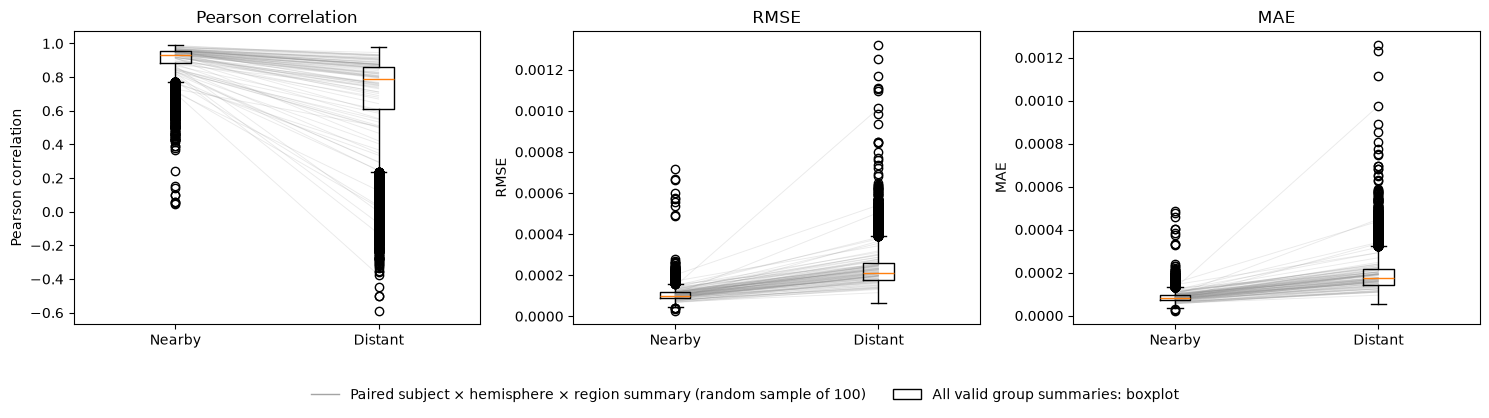

In [4]:
def paired_result(near,far,positive_delta=True):
    delta=near-far if positive_delta else far-near
    stat,p=wilcoxon(delta.dropna())
    return {'nearby_median':near.median(),'distant_median':far.median(),'median_delta':delta.median(),'wilcoxon_p':p,'n_groups':delta.notna().sum()}
results=pd.DataFrame([paired_result(summary.nearest_profile_corr,summary.distant_profile_corr,True),paired_result(summary.nearest_profile_rmse,summary.distant_profile_rmse,False),paired_result(summary.nearest_profile_mae,summary.distant_profile_mae,False)],index=['Profile correlation','Profile RMSE','Profile MAE'])
display(results)
plot_rows=summary.sample(min(100,len(summary)),random_state=42)
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,near,far,label in zip(axes,['nearest_profile_corr','nearest_profile_rmse','nearest_profile_mae'],['distant_profile_corr','distant_profile_rmse','distant_profile_mae'],['Pearson correlation','RMSE','MAE']):
    for _,row in plot_rows.iterrows(): ax.plot([1,2],[row[near],row[far]],color='0.55',alpha=.18,lw=.65,zorder=1)
    ax.boxplot([summary[near].dropna(),summary[far].dropna()],tick_labels=['Nearby','Distant'],zorder=2); ax.set(title=label,ylabel=label)
line_handle=Line2D([0],[0],color='0.45',alpha=.65,lw=1,label='Paired subject × hemisphere × region summary (random sample of 100)')
box_handle=Patch(facecolor='white',edgecolor='black',label='All valid group summaries: boxplot')
fig.legend(handles=[line_handle,box_handle],loc='lower center',ncol=2,frameon=False,bbox_to_anchor=(.5,-.05))
fig.tight_layout(rect=(0,.08,1,1)); fig.savefig(QC_ROOT/'02_nearby_vs_distant_similarity.png',dpi=180); plt.show()


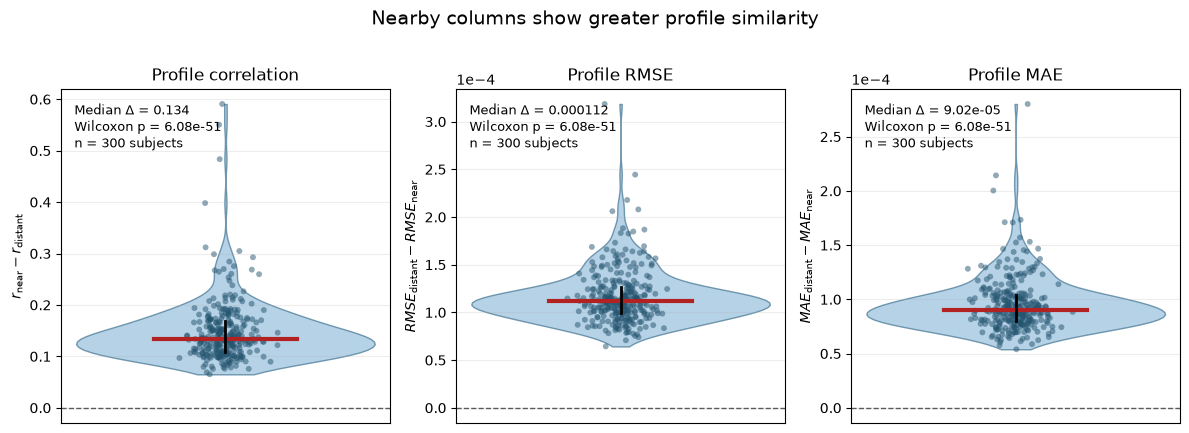

,nearby_median,distant_median,median_delta,wilcoxon_p,n_subjects
metric,,,,,
Profile correlation,0.935880,0.800391,0.133590,6.083560e-51,300
Profile RMSE,0.000098,0.000209,0.000112,6.083560e-51,300
Profile MAE,0.000080,0.000170,0.000090,6.083560e-51,300


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from matplotlib.ticker import ScalarFormatter

# 修改为summary中实际的subject列名
SUBJECT_COL = "subject"

metrics = [
    {
        "near": "nearest_profile_corr",
        "far": "distant_profile_corr",
        "title": "Profile correlation",
        "ylabel": r"$r_{\mathrm{near}}-r_{\mathrm{distant}}$",
        "direction": 1,
    },
    {
        "near": "nearest_profile_rmse",
        "far": "distant_profile_rmse",
        "title": "Profile RMSE",
        "ylabel": r"$RMSE_{\mathrm{distant}}-RMSE_{\mathrm{near}}$",
        "direction": -1,
    },
    {
        "near": "nearest_profile_mae",
        "far": "distant_profile_mae",
        "title": "Profile MAE",
        "ylabel": r"$MAE_{\mathrm{distant}}-MAE_{\mathrm{near}}$",
        "direction": -1,
    },
]

# 每个subject先汇总，避免subject-region伪重复
needed_columns = [SUBJECT_COL] + [
    column
    for metric in metrics
    for column in [metric["near"], metric["far"]]
]

subject_summary = (
    summary[needed_columns]
    .groupby(SUBJECT_COL, as_index=False)
    .median(numeric_only=True)
)

rng = np.random.default_rng(42)

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))

result_rows = []

for ax, metric in zip(axes, metrics):

    near = subject_summary[metric["near"]]
    far = subject_summary[metric["far"]]

    if metric["direction"] == 1:
        delta = near - far
    else:
        delta = far - near

    delta = delta.dropna()

    if len(delta) > 0 and np.any(delta != 0):
        _, p_value = wilcoxon(delta)
    else:
        p_value = np.nan

    median_delta = delta.median()

    # Violin
    violin = ax.violinplot(
        delta,
        positions=[1],
        widths=0.75,
        showmeans=False,
        showmedians=False,
        showextrema=False,
    )

    for body in violin["bodies"]:
        body.set_facecolor("#8FBBD9")
        body.set_edgecolor("#356A8A")
        body.set_alpha(0.65)

    # Jittered subject points
    jitter = rng.normal(1, 0.045, size=len(delta))
    ax.scatter(
        jitter,
        delta,
        s=18,
        color="#24546F",
        alpha=0.50,
        edgecolors="none",
        zorder=3,
    )

    # Median and IQR
    q1, q3 = delta.quantile([0.25, 0.75])

    ax.plot(
        [0.82, 1.18],
        [median_delta, median_delta],
        color="#B22222",
        linewidth=3,
        zorder=4,
    )

    ax.plot(
        [1, 1],
        [q1, q3],
        color="black",
        linewidth=2,
        zorder=4,
    )

    # Null reference
    ax.axhline(0, color="0.35", linestyle="--", linewidth=1)

    ax.set_xticks([])
    ax.set_title(metric["title"], fontsize=12)
    ax.set_ylabel(metric["ylabel"])
    ax.grid(axis="y", alpha=0.22)

    p_text = f"{p_value:.2e}" if np.isfinite(p_value) else "NA"

    ax.text(
        0.04,
        0.96,
        f"Median Δ = {median_delta:.3g}\n"
        f"Wilcoxon p = {p_text}\n"
        f"n = {len(delta)} subjects",
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=9,
    )

    if "correlation" not in metric["title"].lower():
        ax.ticklabel_format(axis="y", style="sci", scilimits=(-3, 3))

    result_rows.append({
        "metric": metric["title"],
        "nearby_median": near.median(),
        "distant_median": far.median(),
        "median_delta": median_delta,
        "wilcoxon_p": p_value,
        "n_subjects": len(delta),
    })

fig.suptitle(
    "Nearby columns show greater profile similarity",
    fontsize=14,
    y=1.02,
)

fig.tight_layout()
fig.savefig(
    QC_ROOT / "02_nearby_vs_distant_subject_level_delta.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

results_subject_level = pd.DataFrame(result_rows).set_index("metric")
display(results_subject_level)

## 3. Continuous distance–similarity trend

Random column pairs are ranked into six within-group distance bins. The plot shows the median across subject-region groups, with IQR.


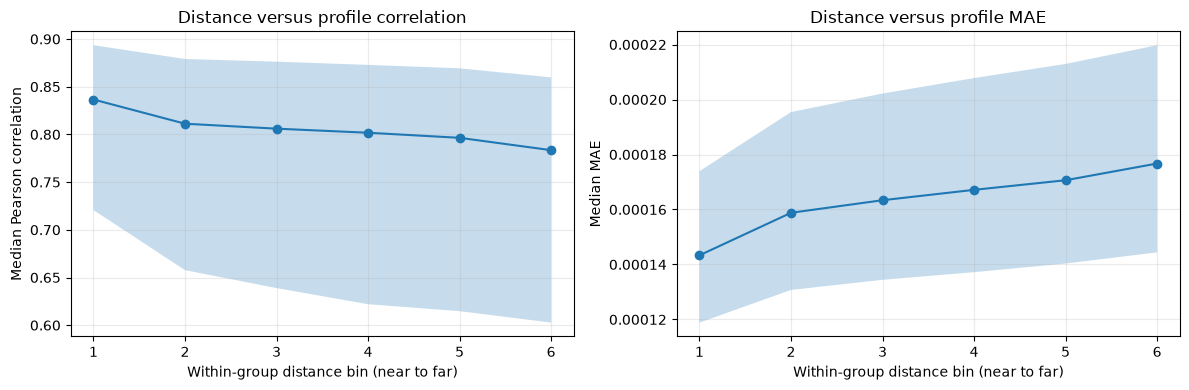

,distance_profile_corr_spearman,distance_profile_mae_spearman,distance_profile_rmse_spearman
count,20317.000000,20317.000000,20317.000000
mean,-0.057235,0.097169,0.098456
std,0.058410,0.079454,0.078084
min,-0.467333,-0.099747,-0.095153
25%,-0.091305,0.041873,0.044048
50%,-0.052259,0.082303,0.084180
75%,-0.017838,0.136959,0.138035
max,0.134989,0.636182,0.600892


In [6]:
def cohort_bin_curve(value):
    return bins.groupby('distance_bin')[value].agg(q25=lambda x:x.quantile(.25),median='median',q75=lambda x:x.quantile(.75)).reset_index()
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,value,title,ylabel in [(axes[0],'profile_corr_median','Distance versus profile correlation','Median Pearson correlation'),(axes[1],'profile_mae_median','Distance versus profile MAE','Median MAE')]:
    curve=cohort_bin_curve(value); ax.plot(curve.distance_bin,curve['median'],marker='o'); ax.fill_between(curve.distance_bin,curve.q25,curve.q75,alpha=.25); ax.set(title=title,xlabel='Within-group distance bin (near to far)',ylabel=ylabel); ax.grid(alpha=.25)
fig.tight_layout(); fig.savefig(QC_ROOT/'03_distance_similarity_trend.png',dpi=180); plt.show()
display(summary[['distance_profile_corr_spearman','distance_profile_mae_spearman','distance_profile_rmse_spearman']].describe())


## 4. Region-level nearby advantage

Values are the median nearby-minus-distant correlation effect across subjects.


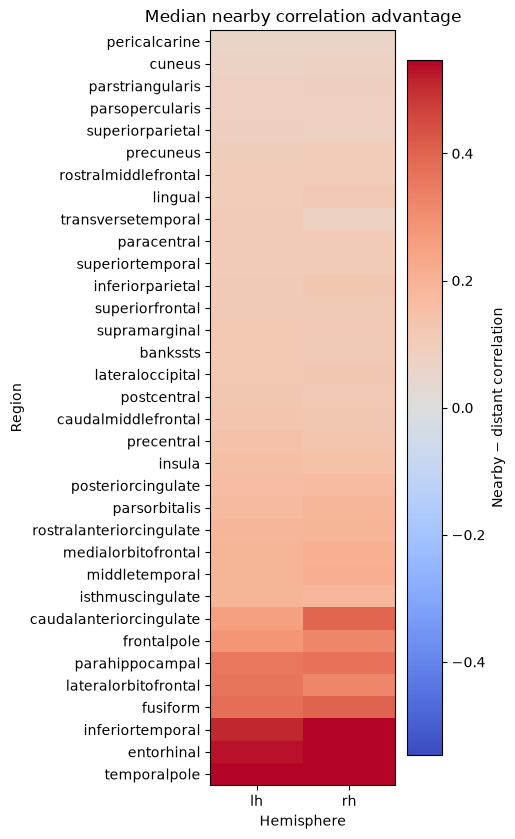

In [7]:
region=summary.groupby(['hemisphere','region'],as_index=False).delta_r.median(); pivot=region.pivot(index='region',columns='hemisphere',values='delta_r').sort_values(['lh','rh'],na_position='last')
fig,ax=plt.subplots(figsize=(5,max(8,.25*len(pivot)))); image=ax.imshow(pivot.to_numpy(),aspect='auto',cmap='coolwarm',vmin=-np.nanpercentile(np.abs(pivot),95),vmax=np.nanpercentile(np.abs(pivot),95)); ax.set(title='Median nearby correlation advantage',xlabel='Hemisphere',ylabel='Region',xticks=range(len(pivot.columns)),xticklabels=pivot.columns,yticks=range(len(pivot.index)),yticklabels=pivot.index); fig.colorbar(image,ax=ax,label='Nearby − distant correlation'); fig.tight_layout(); fig.savefig(QC_ROOT/'04_region_nearby_advantage.png',dpi=180); plt.show()


### Region-level distance check

This tests whether regions with a larger nearby-minus-distant correlation advantage also have unusually small nearby distances or unusually large distant distances. All quantities are medians across subjects within each hemisphere × region.


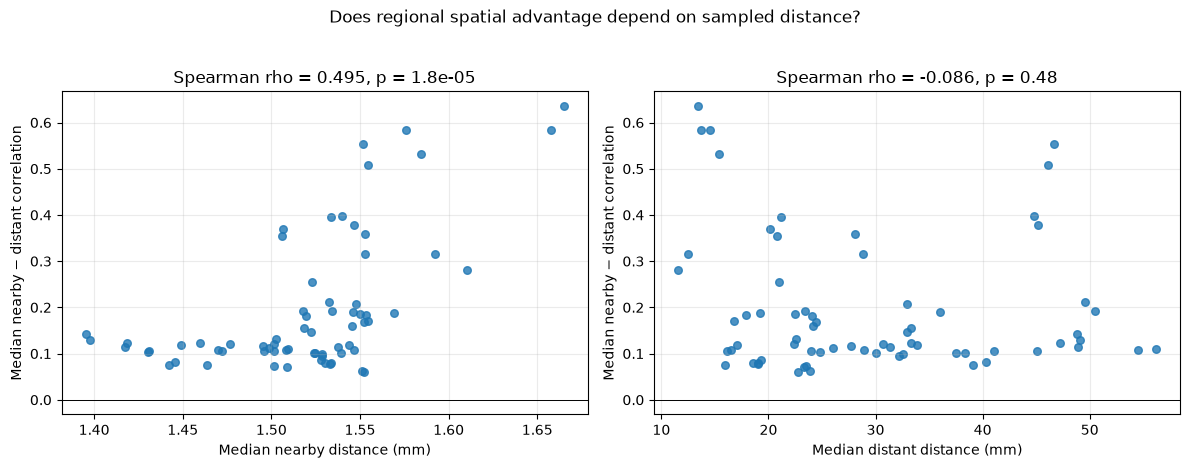

,hemisphere,region,spatial_effect_delta_r,nearby_distance_mm,distant_distance_mm,distance_gap_mm,distance_ratio,n_subject_region_groups,region_label
32,lh,temporalpole,0.635690,1.664845,13.384142,11.719297,8.006048,297,lh_temporalpole
66,rh,temporalpole,0.584449,1.657938,13.685313,12.027375,8.237987,297,rh_temporalpole
38,rh,entorhinal,0.583151,1.576068,14.508827,12.932759,9.186788,297,rh_entorhinal
42,rh,inferiortemporal,0.553663,1.551440,46.697675,45.146234,30.037353,298,rh_inferiortemporal
4,lh,entorhinal,0.532547,1.584396,15.345240,13.760844,9.676850,298,lh_entorhinal
8,lh,inferiortemporal,0.508541,1.554514,46.074553,44.520039,29.667068,299,lh_inferiortemporal
40,rh,fusiform,0.397271,1.539560,44.797964,43.258404,29.030826,298,rh_fusiform
35,rh,caudalanteriorcingulate,0.395250,1.533354,21.157027,19.623674,13.772950,299,rh_caudalanteriorcingulate
6,lh,fusiform,0.378106,1.546745,45.189096,43.642352,29.008409,299,lh_fusiform
51,rh,parahippocampal,0.369128,1.506268,20.133617,18.627349,13.373281,298,rh_parahippocampal


In [8]:
from scipy.stats import spearmanr
region_distance_check=summary.groupby(['hemisphere','region'],as_index=False).agg(spatial_effect_delta_r=('delta_r','median'),nearby_distance_mm=('nearest_mean_distance_mm','median'),distant_distance_mm=('distant_mean_distance_mm','median'),distance_gap_mm=('distant_mean_distance_mm',lambda x: np.nanmedian(x)-np.nanmedian(summary.loc[x.index,'nearest_mean_distance_mm'])),distance_ratio=('distant_mean_distance_mm',lambda x: np.nanmedian(x/summary.loc[x.index,'nearest_mean_distance_mm'])),n_subject_region_groups=('delta_r','size'))
region_distance_check['region_label']=region_distance_check.hemisphere+'_'+region_distance_check.region
region_distance_check.to_csv(QC_ROOT/'04_region_effect_distance_check.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(12,4.5)); checks=[('nearby_distance_mm','Median nearby distance (mm)'),('distant_distance_mm','Median distant distance (mm)')]
for ax,(column,xlabel) in zip(axes,checks):
    d=region_distance_check[['spatial_effect_delta_r',column]].dropna(); rho,p=spearmanr(d[column],d.spatial_effect_delta_r)
    ax.scatter(d[column],d.spatial_effect_delta_r,s=30,alpha=.8); ax.set(title=f'Spearman rho = {rho:.3f}, p = {p:.2g}',xlabel=xlabel,ylabel='Median nearby − distant correlation'); ax.axhline(0,color='black',lw=.7); ax.grid(alpha=.25)
fig.suptitle('Does regional spatial advantage depend on sampled distance?',y=1.03); fig.tight_layout(); fig.savefig(QC_ROOT/'04_region_effect_distance_check.png',dpi=180); plt.show()
display(region_distance_check.sort_values('spatial_effect_delta_r',ascending=False).head(20))


## 5. Comparison of high spatial effect and high regional CV

Spatial effect strength is the median nearby-minus-distant profile correlation (delta_r) across subjects for each hemisphere × region. It is compared with the median MD regional CV from the separate population-CV summary.


Spatial-effect top 20: 20; CV top 20: 20; overlap: 10


,region_label,spatial_effect_delta_r,spatial_effect_rank,regional_cv_pct,regional_cv_rank
32,lh_temporalpole,0.635690,1.0,25.229776,16.0
66,rh_temporalpole,0.584449,2.0,27.270057,11.0
38,rh_entorhinal,0.583151,3.0,24.982750,19.0
42,rh_inferiortemporal,0.553663,4.0,28.868512,7.0
4,lh_entorhinal,0.532547,5.0,24.204021,23.0
8,lh_inferiortemporal,0.508541,6.0,27.199779,12.0
40,rh_fusiform,0.397271,7.0,22.617200,34.0
35,rh_caudalanteriorcingulate,0.395250,8.0,20.241352,39.0
6,lh_fusiform,0.378106,9.0,19.978683,41.0
51,rh_parahippocampal,0.369128,10.0,25.422625,14.0


,region_label,regional_cv_pct,regional_cv_rank,spatial_effect_delta_r,spatial_effect_rank
22,lh_postcentral,32.934239,1.0,0.123479,34.0
56,rh_postcentral,32.781676,2.0,0.113619,42.0
10,lh_isthmuscingulate,32.739149,3.0,0.191668,19.0
44,rh_isthmuscingulate,31.183543,4.0,0.181640,25.0
14,lh_medialorbitofrontal,29.718607,5.0,0.190502,21.0
47,rh_lingual,28.892026,6.0,0.114665,41.0
42,rh_inferiortemporal,28.868512,7.0,0.553663,4.0
13,lh_lingual,27.980627,8.0,0.101870,53.0
17,lh_parahippocampal,27.560298,9.0,0.355375,12.0
48,rh_medialorbitofrontal,27.496865,10.0,0.207931,18.0


,region_label,spatial_effect_delta_r,spatial_effect_rank,regional_cv_pct,regional_cv_rank
32,lh_temporalpole,0.635690,1.0,25.229776,16.0
66,rh_temporalpole,0.584449,2.0,27.270057,11.0
38,rh_entorhinal,0.583151,3.0,24.982750,19.0
42,rh_inferiortemporal,0.553663,4.0,28.868512,7.0
8,lh_inferiortemporal,0.508541,6.0,27.199779,12.0
51,rh_parahippocampal,0.369128,10.0,25.422625,14.0
17,lh_parahippocampal,0.355375,12.0,27.560298,9.0
46,rh_lateralorbitofrontal,0.316554,13.0,24.685840,20.0
48,rh_medialorbitofrontal,0.207931,18.0,27.496865,10.0
10,lh_isthmuscingulate,0.191668,19.0,32.739149,3.0


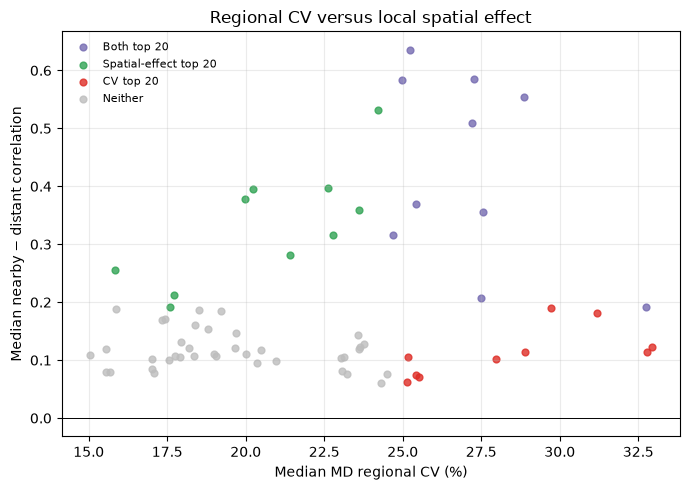

In [9]:
CV_RESULTS=Path('/mnt/newStor/paros/paros_WORK/xintong/results/profile_stability/regional_ci_cv_summary.csv')
if not CV_RESULTS.is_file(): raise FileNotFoundError(f'Missing regional CV summary: {CV_RESULTS}')
cv_raw=pd.read_csv(CV_RESULTS); cv=cv_raw[cv_raw.status.eq('valid') & cv_raw.metric.eq('md')].copy()
spatial_region=summary.groupby(['hemisphere','region'],as_index=False).agg(spatial_effect_delta_r=('delta_r','median'),spatial_groups=('delta_r','size'))
cv_region=cv.groupby(['hemi','region'],as_index=False).agg(regional_cv_pct=('regional_cv_pct','median'),cv_subjects=('subject','nunique')).rename(columns={'hemi':'hemisphere'})
comparison=spatial_region.merge(cv_region,on=['hemisphere','region'],how='outer'); comparison['region_label']=comparison.hemisphere+'_'+comparison.region
comparison['spatial_effect_rank']=comparison.spatial_effect_delta_r.rank(method='min',ascending=False); comparison['regional_cv_rank']=comparison.regional_cv_pct.rank(method='min',ascending=False)
comparison['spatial_effect_top20']=comparison.spatial_effect_rank.le(20); comparison['regional_cv_top20']=comparison.regional_cv_rank.le(20)
comparison['top20_membership']=np.select([comparison.spatial_effect_top20 & comparison.regional_cv_top20,comparison.spatial_effect_top20,comparison.regional_cv_top20],['Both top 20','Spatial-effect top 20','CV top 20'],default='Neither')
comparison=comparison.sort_values('spatial_effect_rank'); comparison.to_csv(QC_ROOT/'05_spatial_effect_vs_regional_cv.csv',index=False)
spatial_top20=comparison[comparison.spatial_effect_top20].sort_values('spatial_effect_rank'); cv_top20=comparison[comparison.regional_cv_top20].sort_values('regional_cv_rank'); overlap=comparison[comparison.spatial_effect_top20 & comparison.regional_cv_top20].sort_values('spatial_effect_rank')
print(f'Spatial-effect top 20: {len(spatial_top20)}; CV top 20: {len(cv_top20)}; overlap: {len(overlap)}')
display(spatial_top20[['region_label','spatial_effect_delta_r','spatial_effect_rank','regional_cv_pct','regional_cv_rank']])
display(cv_top20[['region_label','regional_cv_pct','regional_cv_rank','spatial_effect_delta_r','spatial_effect_rank']])
display(overlap[['region_label','spatial_effect_delta_r','spatial_effect_rank','regional_cv_pct','regional_cv_rank']])
fig,ax=plt.subplots(figsize=(7,5)); colors={'Both top 20':'#756bb1','Spatial-effect top 20':'#31a354','CV top 20':'#de2d26','Neither':'#bdbdbd'}
for label,color in colors.items():
    g=comparison[comparison.top20_membership.eq(label)]; ax.scatter(g.regional_cv_pct,g.spatial_effect_delta_r,s=24,alpha=.8,color=color,label=label)
ax.set(title='Regional CV versus local spatial effect',xlabel='Median MD regional CV (%)',ylabel='Median nearby − distant correlation'); ax.axhline(0,color='black',lw=.7); ax.grid(alpha=.25); ax.legend(frameon=False,fontsize=8); fig.tight_layout(); fig.savefig(QC_ROOT/'05_spatial_effect_vs_regional_cv.png',dpi=180); plt.show()


## Native and fsaverage surface resolution

Compare native subject vertex counts with common fsaverage template resolutions. Counts are per hemisphere; native counts are read from each subject's `sphere.reg` surface.


In [10]:
from nibabel.freesurfer.io import read_geometry

SUBJECTS_DIR = Path('/mnt/newStor/paros/paros_WORK/xintong/data/processed/t1_freesurfer')
FSAVERAGE_DIR = Path('/home/apps/freesurfer/subjects')
template_vertices = {'fsaverage': 163842, 'fsaverage6': 40962, 'fsaverage5': 10242, 'fsaverage4': 2562, 'fsaverage3': 642}
rows = []
for subject_dir in sorted(p for p in SUBJECTS_DIR.glob('D*') if p.is_dir()):
    for hemi in ('lh', 'rh'):
        surface = subject_dir / 'surf' / f'{hemi}.sphere.reg'
        if surface.is_file():
            rows.append({'subject_id': subject_dir.name, 'hemisphere': hemi, 'native_vertices': len(read_geometry(str(surface))[0])})
native_vertices = pd.DataFrame(rows)
template_table = pd.DataFrame([{'template': k, 'vertices_per_hemisphere': v, 'total_vertices': 2*v} for k, v in template_vertices.items()])
display(native_vertices.describe(include='all'))
display(template_table)
native_vertices.to_csv(QC_ROOT / 'native_surface_vertex_counts.csv', index=False)
template_table.to_csv(QC_ROOT / 'fsaverage_template_vertex_counts.csv', index=False)


,subject_id,hemisphere,native_vertices
count,674,674,674.000000
unique,337,2,NaN
top,D0007,lh,NaN
freq,2,337,NaN
mean,NaN,NaN,131057.402077
std,NaN,NaN,12972.726259
min,NaN,NaN,77805.000000
25%,NaN,NaN,121592.750000
50%,NaN,NaN,131256.500000
75%,NaN,NaN,139112.250000


,template,vertices_per_hemisphere,total_vertices
0,fsaverage,163842,327684
1,fsaverage6,40962,81924
2,fsaverage5,10242,20484
3,fsaverage4,2562,5124
4,fsaverage3,642,1284
